# EDA posterior a la selección: español → quechua chanka → grabación

Este notebook compara las etapas del corpus, recupera el español de las flashcards como referencia y analiza los candidatos de grabación. **No aprueba traducciones, no cambia bloques y no modifica los originales.**

Ejecutar las celdas en orden. Las tablas y figuras se escriben en `04_reportes/eda_postseleccion/`; la plantilla de revisión humana se crea una sola vez para conservar las anotaciones al volver a ejecutar.

Las flashcards incluyen otra lengua: se usa **solo su español**, nunca sus traducciones como quechua. Coincidencia léxica, alineación y aprobación son conceptos distintos.


In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import hashlib, json, re, unicodedata
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Si se mueve el proyecto, indicar aquí las rutas de las flashcards.
FLASHCARDS_DIR = None
SEED = 20261018
MAX_PALABRAS_ALERTA = 20  # Señal para revisión; nunca descarte automático.
busqueda = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in busqueda if (p/'02_maestro/corpus_maestro.xlsx').exists()), None)
if ROOT is None:
    ROOT = next((p/'EDA_AnalisisFinal/Corpus_Quechua' for p in busqueda
                 if (p/'EDA_AnalisisFinal/Corpus_Quechua/02_maestro/corpus_maestro.xlsx').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Ejecuta desde Corpus_Quechua o desde su workspace.')
OUT = ROOT/'04_reportes/eda_postseleccion'
OUT.mkdir(parents=True, exist_ok=True)
FIG = OUT/'fig'; FIG.mkdir(exist_ok=True)
if FLASHCARDS_DIR is None:
    FLASHCARDS_DIR = next((p for p in [ROOT, *ROOT.parents] if (p/'flashcards.xlsx').exists()), ROOT/'Fuentes')
else:
    FLASHCARDS_DIR = Path(FLASHCARDS_DIR)

def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def limpiar(s): return unicodedata.normalize('NFC', str(s)).strip()
def tokens(s): return re.findall(r"[a-záéíóúüñ]+(?:['’][a-záéíóúüñ]+)?|[0-9]+", limpiar(s).lower())
def vocab(textos): return set(t for s in textos for t in tokens(s))
def clave_conservadora(s): return re.sub(r'\s+', ' ', limpiar(s)).casefold()
def clave_flexible(s):
    s = ''.join(c for c in unicodedata.normalize('NFD', limpiar(s).lower()) if unicodedata.category(c) != 'Mn')
    return re.sub(r'[^a-z0-9]+', ' ', s).strip()
def guardar_fig(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG/nombre, dpi=150, bbox_inches='tight'); plt.show()
def checkpoint(fase):
    paths = sorted((ROOT/'02_maestro/checkpoints').glob(f'{fase}_*.xlsx'))
    if not paths: raise FileNotFoundError(f'Sin checkpoint {fase}')
    return paths[-1]

entradas = [ROOT/'02_maestro/corpus_maestro.xlsx', checkpoint('F2_ingesta'), checkpoint('F4_limpio'), checkpoint('F5_huecos')]
H = pd.read_excel(entradas[0], sheet_name=None, dtype=str)
H = {k:v.fillna('') for k,v in H.items()}
C, O, QA = H['Corpus'], H['Origen'], H['QA']
assert C.ID.is_unique and O.ID.is_unique, 'Revisar IDs duplicados antes de analizar.'
assert set(C.ID) == set(O.ID), 'Corpus y Origen no contienen los mismos IDs.'
M = C.merge(O, on='ID', validate='one_to_one')
S = M[M.Bloque.ne('')].copy()
S['orden_bloque'] = pd.to_numeric(S.N_bloque, errors='raise')
S = S.sort_values(['Bloque','orden_bloque']).reset_index(drop=True)
F2 = pd.read_excel(entradas[1], sheet_name='Registros', dtype=str).fillna('')
F4 = pd.read_excel(entradas[2], sheet_name='Corpus', dtype=str).fillna('')
F5 = pd.read_excel(entradas[3], sheet_name='Corpus', dtype=str).fillna('')
huellas = {str(p):sha(p) for p in entradas}
assert set(F5.ID) == set(C.ID), 'F5 y maestro no corresponden: elige explícitamente el checkpoint correcto.'
assert F5.set_index('ID')['Español'].sort_index().equals(C.set_index('ID')['Español'].sort_index()), 'Cambió el español entre F5 y maestro; revisar versiones.'
print(f'Maestro: {len(M):,}; seleccionados: {len(S):,}; quechua validado: {C.Quechua_validado.ne("").sum()}')
display(pd.DataFrame({'archivo':[p.name for p in entradas], 'sha256':[huellas[str(p)] for p in entradas]}))


Maestro: 2,254; seleccionados: 1,000; quechua validado: 0


,archivo,sha256
0,corpus_maestro.xlsx,ca52cc9383e92560a5c95f48b532340c2645ed10977e2d...
1,F2_ingesta_20261015.xlsx,8c103eb2555d57906431316ead9eb764bc9c6984b5ee3e...
2,F4_limpio_20261015.xlsx,8ca0b20b040c108f81f9f363dbf1739947f90e3c9cb69c...
3,F5_huecos_20261015.xlsx,037ccdc2e581fc026d162e6704edc7f0e7fb84fe786117...


## 1. ¿Qué cambia entre recopilación, limpieza y selección?

F2 incluye términos y registros que luego se separan o dividen. F4 contiene frases limpias; F5 añade español nuevo. Por ello estos recuentos **no son un embudo de descarte simple**. El maestro puede tener decisiones posteriores. Los rasgos de español siguientes se detectan con reglas y pueden solaparse.


,Etapa,Filas,ES_no_vacio,Con_borrador_QU,Vocabulario_ES,Mediana_palabras,P90_palabras,Preguntas,Negacion_aprox,Con_numeros_digitos,Mas_20_palabras
0,F2 recopilado,2314,2310,1941,2242,4.0,8.0,641,351,32,19
1,F4 limpio,1716,1716,1364,1780,5.0,8.0,636,315,13,0
2,F5 ampliado,2254,2254,1364,2302,5.0,8.0,677,369,13,0
3,Maestro actual,2254,2254,1364,2302,5.0,8.0,677,369,13,0
4,Seleccionado,1000,1000,470,1522,6.0,8.0,186,96,0,0


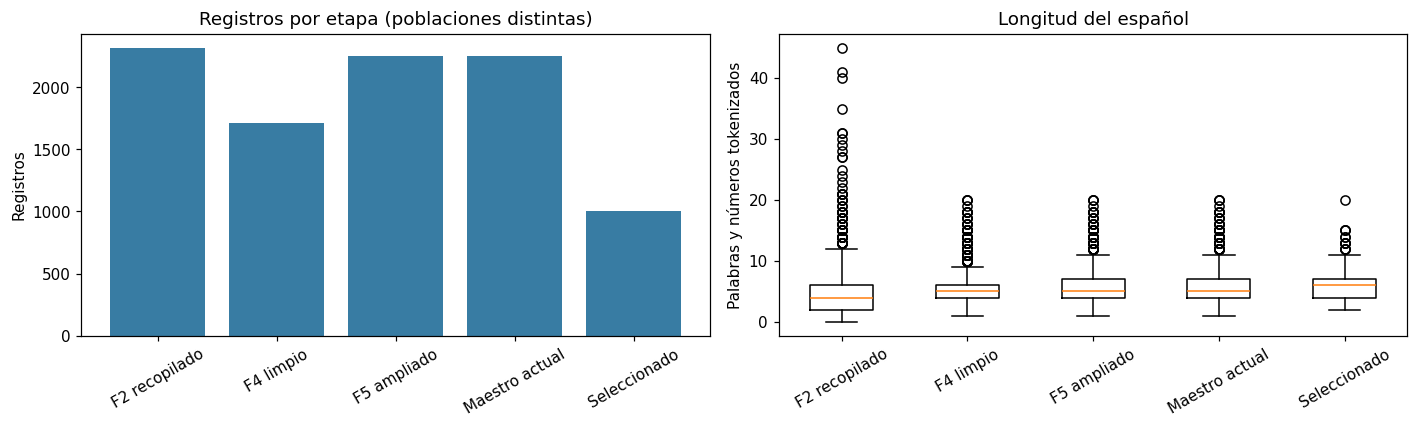

,Etapa,Dominio,Rol,n
0,F2 recopilado,General,—,786
1,F2 recopilado,Médico,Médico,941
2,F2 recopilado,Médico,Paciente,42
3,F2 recopilado,Médico,—,545
4,F4 limpio,General,—,739
5,F4 limpio,Médico,Médico,938
6,F4 limpio,Médico,Paciente,39
7,F5 ampliado,General,—,1114
8,F5 ampliado,Médico,Médico,939
9,F5 ampliado,Médico,Paciente,201


,Etapa,Fuente,Filas,Porcentaje_etapa
0,F2 recopilado,Afiche MINSA/MinCul lavado de manos (chanka),6,0.259291
1,F2 recopilado,Allin Kawsay (INS/MINSA),510,22.039758
2,F2 recopilado,"Farfán Cantero (2001), SITUA",24,1.037165
3,F2 recopilado,Grupo 1 – El Principito,113,4.883319
4,F2 recopilado,Grupo 2 – Corpus Chanka,673,29.083838
...,...,...,...,...
61,Seleccionado,MinCul – manual de justicia (chanka),6,0.600000
62,Seleccionado,OPS/OMS Bolivia (2013),16,1.600000
63,Seleccionado,Redactado por Claude (F5),504,50.400000
64,Seleccionado,SOCEMURP (corpus original del equipo),27,2.700000


In [2]:
etapas = {'F2 recopilado':F2, 'F4 limpio':F4, 'F5 ampliado':F5, 'Maestro actual':M, 'Seleccionado':S}
resumen, largos = [], []
for nombre, df in etapas.items():
    es = df['Español']; n = es.map(lambda s:len(tokens(s)))
    resumen.append({'Etapa':nombre,'Filas':len(df),'ES_no_vacio':es.str.strip().ne('').sum(),
        'Con_borrador_QU':df.Quechua_borrador.str.strip().ne('').sum(), 'Vocabulario_ES':len(vocab(es)),
        'Mediana_palabras':n.median(),'P90_palabras':n.quantile(.9),
        'Preguntas':es.str.contains(r'[¿?]',regex=True).sum(),
        'Negacion_aprox':es.str.contains(r'(?i)\b(?:no|nunca|tampoco|jamás)\b',regex=True).sum(),
        'Con_numeros_digitos':es.str.contains(r'\d',regex=True).sum(),
        'Mas_20_palabras':n.gt(MAX_PALABRAS_ALERTA).sum()})
    largos.append(n.to_numpy())
T_ETAPAS = pd.DataFrame(resumen)
display(T_ETAPAS)
fig, axes = plt.subplots(1,2,figsize=(13,4))
axes[0].bar(T_ETAPAS.Etapa, T_ETAPAS.Filas,color='#387ca3'); axes[0].tick_params(axis='x',rotation=30)
axes[0].set_title('Registros por etapa (poblaciones distintas)'); axes[0].set_ylabel('Registros')
axes[1].boxplot(largos, tick_labels=list(etapas), showfliers=True); axes[1].tick_params(axis='x',rotation=30)
axes[1].set_title('Longitud del español'); axes[1].set_ylabel('Palabras y números tokenizados')
guardar_fig(fig,'01_etapas_longitud.png')
T_DISTRIBUCIONES = pd.concat([df.assign(Etapa=n) for n,df in etapas.items()],ignore_index=True)
T_DISTRIBUCIONES = T_DISTRIBUCIONES.groupby(['Etapa','Dominio','Rol'],dropna=False).size().reset_index(name='n')
display(T_DISTRIBUCIONES)
T_FUENTES_ETAPA=pd.concat([df.assign(Etapa=n) for n,df in etapas.items()],ignore_index=True)
T_FUENTES_ETAPA=T_FUENTES_ETAPA.groupby(['Etapa','Fuente']).size().reset_index(name='Filas')
T_FUENTES_ETAPA['Porcentaje_etapa']=100*T_FUENTES_ETAPA.Filas/T_FUENTES_ETAPA.groupby('Etapa').Filas.transform('sum')
display(T_FUENTES_ETAPA)


## 2. Recuperar el español de las flashcards

Se incluyen las columnas identificadas explícitamente: `Sheet1/TEXTO_SPA`, `Sheet2/primera columna` y `es/primera columna` de flashcards.xlsx; `Sheet1/ESP` de flashcards2.xlsx. Las dos hojas sin cabecera española se leen sin perder la primera fila. Se conserva procedencia y se deduplican textos solo para los denominadores de cobertura. Las hojas de la otra lengua se excluyen.

No se lematiza automáticamente: las tildes, la ñ y las formas verbales se conservan. Estas cifras miden formas escritas, no conceptos ni dominio gramatical. Si faltan los archivos, se detiene el análisis para evitar presentar cobertura ficticia.


In [3]:
refs, carga_flash = [], []
esquema = [('flashcards.xlsx','Sheet1','TEXTO_SPA',0),('flashcards.xlsx','Sheet2',0,None),
           ('flashcards.xlsx','es',0,None),('flashcards2.xlsx','Sheet1','ESP',0)]
for archivo, hoja, columna, header in esquema:
    p = FLASHCARDS_DIR/archivo
    if not p.exists(): raise FileNotFoundError(f'Falta {p}. Ajusta FLASHCARDS_DIR en la primera celda.')
    huellas[str(p)] = sha(p)
    df = pd.read_excel(p,sheet_name=hoja,header=header,dtype=str).fillna('')
    serie = df.iloc[:,columna] if isinstance(columna,int) else df[columna]
    validas = 0
    for i,s in enumerate(serie):
        s = limpiar(s)
        if not s or not tokens(s): continue
        refs.append({'Archivo':archivo,'Hoja':hoja,'Fila_excel':i+(2 if header==0 else 1),'Español_ref':s,'Clave':clave_conservadora(s)})
        validas += 1
    carga_flash.append({'Archivo':archivo,'Hoja':hoja,'Filas_leidas':len(df),'Con_texto_ES':validas})
REF_TODAS = pd.DataFrame(refs)
REF = REF_TODAS.drop_duplicates('Clave').copy()
OBJETIVO = vocab(REF.Español_ref)
assert OBJETIVO, 'No hay vocabulario español de referencia.'
display(pd.DataFrame(carga_flash))
print(f'Referencias con procedencia: {len(REF_TODAS)}; textos únicos conservadores: {len(REF)}; formas objetivo: {len(OBJETIVO)}')


,Archivo,Hoja,Filas_leidas,Con_texto_ES
0,flashcards.xlsx,Sheet1,670,669
1,flashcards.xlsx,Sheet2,47,44
2,flashcards.xlsx,es,385,385
3,flashcards2.xlsx,Sheet1,7789,7789


Referencias con procedencia: 8887; textos únicos conservadores: 8247; formas objetivo: 4627


## 3. Cobertura objetivo y palabras que faltan

Cobertura = formas objetivo presentes / todas las formas objetivo. También se muestra cobertura ponderada por frecuencia en los textos de referencia únicos; no debe confundirse con diversidad. El cuadro por palabra permite distinguir vocabulario ausente del maestro de vocabulario disponible, pero no seleccionado.


,Etapa,Formas_objetivo,Formas_cubiertas,Cobertura_tipos_pct,Cobertura_ponderada_pct
0,F2 recopilado,4627,1113,24.05,65.71
1,F4 limpio,4627,1027,22.20,64.43
2,F5 ampliado,4627,1239,26.78,70.14
3,Maestro actual,4627,1239,26.78,70.14
4,Seleccionado,4627,954,20.62,65.34


,Palabra,Frecuencia_referencia,Tokens_maestro,Tokens_seleccionados,Frases_seleccionadas,Situacion
4271,tom,392,0,0,0,ausente_del_maestro
1213,debería,108,0,0,0,ausente_del_maestro
615,café,66,0,0,0,ausente_del_maestro
4177,sólo,49,1,0,0,disponible_no_seleccionada
2069,francés,44,0,0,0,ausente_del_maestro
2286,hiciste,42,0,0,0,ausente_del_maestro
198,allí,41,0,0,0,ausente_del_maestro
2990,necesitas,40,0,0,0,ausente_del_maestro
197,allá,39,0,0,0,ausente_del_maestro
965,conmigo,38,0,0,0,ausente_del_maestro


,Archivo,Etapa,Textos_unicos,Formas_objetivo,Formas_cubiertas,Cobertura_tipos_pct
0,flashcards.xlsx,Maestro actual,704,563,540,95.91
1,flashcards.xlsx,Seleccionado,704,563,470,83.48
2,flashcards2.xlsx,Maestro actual,7543,4375,1009,23.06
3,flashcards2.xlsx,Seleccionado,7543,4375,769,17.58


La referencia combinada contiene muchas más frases de flashcards2.xlsx. Comparar también cada archivo por separado; cobertura baja no equivale a mala traducción.


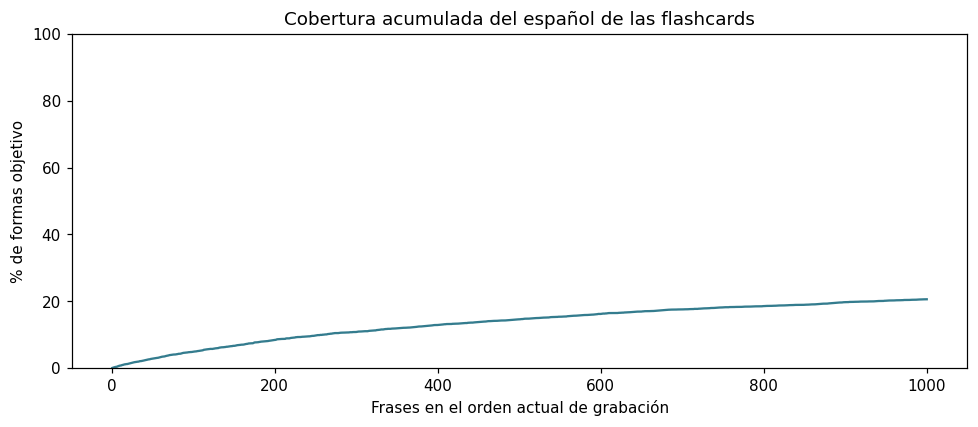

In [4]:
freq_ref = Counter(t for s in REF.Español_ref for t in tokens(s))
freq_m = Counter(t for s in M['Español'] for t in tokens(s))
freq_s = Counter(t for s in S['Español'] for t in tokens(s))
docfreq_s = Counter(t for s in S['Español'] for t in set(tokens(s)))
T_COBERTURA = pd.DataFrame([{'Etapa':nombre,'Formas_objetivo':len(OBJETIVO),
    'Formas_cubiertas':len(vocab(df['Español']) & OBJETIVO),
    'Cobertura_tipos_pct':100*len(vocab(df['Español']) & OBJETIVO)/len(OBJETIVO),
    'Cobertura_ponderada_pct':100*sum(freq_ref[t] for t in vocab(df['Español']) & OBJETIVO)/sum(freq_ref.values())}
    for nombre,df in etapas.items()])
T_PALABRAS = pd.DataFrame([{'Palabra':t,'Frecuencia_referencia':freq_ref[t],'Tokens_maestro':freq_m[t],
    'Tokens_seleccionados':freq_s[t],'Frases_seleccionadas':docfreq_s[t],
    'Situacion':'cubierta' if freq_s[t] else ('disponible_no_seleccionada' if freq_m[t] else 'ausente_del_maestro')}
    for t in sorted(OBJETIVO)]).sort_values(['Frases_seleccionadas','Frecuencia_referencia'],ascending=[True,False])
display(T_COBERTURA.round(2)); display(T_PALABRAS.head(25))
por_archivo=[]
for archivo,g in REF_TODAS.groupby('Archivo'):
    g=g.drop_duplicates('Clave');vs=vocab(g.Español_ref)
    for nombre,df in [('Maestro actual',M),('Seleccionado',S)]:
        cubiertas=vs & vocab(df['Español'])
        por_archivo.append({'Archivo':archivo,'Etapa':nombre,'Textos_unicos':len(g),'Formas_objetivo':len(vs),
            'Formas_cubiertas':len(cubiertas),'Cobertura_tipos_pct':100*len(cubiertas)/max(1,len(vs))})
T_COBERTURA_ARCHIVO=pd.DataFrame(por_archivo)
display(T_COBERTURA_ARCHIVO.round(2))
print('La referencia combinada contiene muchas más frases de flashcards2.xlsx. Comparar también cada archivo por separado; cobertura baja no equivale a mala traducción.')
seen=set(); curva=[]
for n,r in enumerate(S.to_dict('records'),1):
    new=set(tokens(r['Español'])) & OBJETIVO - seen
    seen.update(set(tokens(r['Español'])) & OBJETIVO)
    curva.append({'n':n,'ID':r['ID'],'Bloque':r['Bloque'],'nuevas_formas_objetivo':len(new),
        'nuevas_formas':' | '.join(sorted(new)),'cobertura_pct':100*len(seen)/len(OBJETIVO)})
T_CURVA=pd.DataFrame(curva)
fig,ax=plt.subplots(figsize=(9,4));ax.plot(T_CURVA.n,T_CURVA.cobertura_pct,color='#347c8e')
ax.set(xlabel='Frases en el orden actual de grabación',ylabel='% de formas objetivo',title='Cobertura acumulada del español de las flashcards',ylim=(0,100))
guardar_fig(fig,'02_cobertura_flashcards.png')


## 4. Recuperar candidatos con su pareja quechua

Por cada referencia se prioriza la coincidencia exacta conservadora; si no existe, se recupera el candidato con mayor Jaccard de conjuntos de palabras (desempate por ID). Es una búsqueda léxica exploratoria, **no similitud semántica ni equivalencia de traducción**. Se devuelve también cobertura de las palabras de la referencia, coincidencia exacta y el par original del maestro. Puede haber candidatos muy débiles; revisar el puntaje y el español antes de reutilizar.

No se trasplanta el quechua del candidato a una referencia distinta. Si se cambia su español, se solicita una nueva traducción. La procedencia completa de referencias duplicadas queda en `Referencias_todas` del Excel.


In [5]:
registros=M.sort_values('ID').to_dict('records')
sets=[set(tokens(r['Español'])) for r in registros]
claves_registros=[clave_conservadora(r['Español']) for r in registros]
indice=defaultdict(set)
for j,ts in enumerate(sets):
    for t in ts: indice[t].add(j)
recuperadas=[]
for r in REF.to_dict('records'):
    ts=set(tokens(r['Español_ref'])); opciones=set().union(*(indice[t] for t in ts)) if ts else set()
    base={k:r[k] for k in ['Archivo','Hoja','Fila_excel','Español_ref']}
    if not opciones:
        recuperadas.append(dict(base,ID='',Jaccard=0,Cobertura_ref=0,Coincidencia_exacta=False));continue
    j=min(opciones,key=lambda j:(r['Clave']!=claves_registros[j],
        -len(ts & sets[j])/max(1,len(ts | sets[j])),registros[j]['ID']))
    c=registros[j]
    base.update({k:c[k] for k in ['ID','Español','Quechua_borrador','Quechua_validado','Fuente','Estado','Bloque','Tipo_borrador']})
    base.update(Jaccard=len(ts&sets[j])/len(ts|sets[j]),Cobertura_ref=len(ts&sets[j])/len(ts),
                Coincidencia_exacta=clave_conservadora(r['Español_ref'])==clave_conservadora(c['Español']))
    recuperadas.append(base)
T_RECUPERADAS=pd.DataFrame(recuperadas)
display(T_RECUPERADAS.sort_values(['Coincidencia_exacta','Jaccard'],ascending=False).head(12))
print('Coincidencias exactas conservadoras:',int(T_RECUPERADAS.Coincidencia_exacta.sum()),'de',len(REF))


,Archivo,Hoja,Fila_excel,Español_ref,ID,Español,Quechua_borrador,Quechua_validado,Fuente,Estado,Bloque,Tipo_borrador,Jaccard,Cobertura_ref,Coincidencia_exacta
0,flashcards.xlsx,Sheet1,2,El niño va corriendo a la chacra.,GEN-0106,El niño va corriendo a la chacra.,Qari warma chakraman kallpaspa rin.,,Grupo 2 – Corpus Chanka,Borrador,B01,MINEDU,1.0,1.0,True
1,flashcards.xlsx,Sheet1,3,El niño está corriendo en la chacra.,GEN-0107,El niño está corriendo en la chacra.,Qari warma chakrapi kallpachkan.,,Grupo 2 – Corpus Chanka,Borrador,B02,MINEDU,1.0,1.0,True
2,flashcards.xlsx,Sheet1,4,La mujer canta una canción.,GEN-0108,La mujer canta una canción.,Warmi huk takita takin.,,Grupo 2 – Corpus Chanka,Borrador,B02,MINEDU,1.0,1.0,True
3,flashcards.xlsx,Sheet1,5,El perro duerme bajo la mesa.,GEN-0109,El perro duerme bajo la mesa.,Allqu misa uranpi puñun.,,Grupo 2 – Corpus Chanka,Borrador,B02,MINEDU,1.0,1.0,True
4,flashcards.xlsx,Sheet1,6,Hoy hace mucho calor.,GEN-0110,Hoy hace mucho calor.,Kunan punchaw ancha quñi.,,Grupo 2 – Corpus Chanka,Borrador,B02,MINEDU,1.0,1.0,True
5,flashcards.xlsx,Sheet1,7,Vamos al río por la tarde.,GEN-0111,Vamos al río por la tarde.,Chisipi mayuman risun.,,Grupo 2 – Corpus Chanka,Borrador,B02,MINEDU,1.0,1.0,True
6,flashcards.xlsx,Sheet1,8,Mamá cocina pescado.,GEN-0112,Mamá cocina pescado.,Mamay challwata yanun.,,Grupo 2 – Corpus Chanka,Borrador,B02,MINEDU,1.0,1.0,True
7,flashcards.xlsx,Sheet1,9,El abuelo cuenta historias.,GEN-0113,El abuelo cuenta historias.,Awilu willakuykunata willan.,,Grupo 2 – Corpus Chanka,Borrador,B01,MINEDU,1.0,1.0,True
8,flashcards.xlsx,Sheet1,10,Me gusta la fruta madura.,GEN-0114,Me gusta la fruta madura.,Puqusqa ruruta munani.,,Grupo 2 – Corpus Chanka,Borrador,B01,MINEDU,1.0,1.0,True
9,flashcards.xlsx,Sheet1,11,El sol sale temprano.,GEN-0115,El sol sale temprano.,Inti tutamanta lluqsimun.,,Grupo 2 – Corpus Chanka,Borrador,B02,MINEDU,1.0,1.0,True


Coincidencias exactas conservadoras: 636 de 8247


## 5. Naturalidad, autonomía y facilidad de grabación

Las reglas siguientes solo priorizan revisión: longitud, varias preguntas, referencias contextuales al inicio y algunas observaciones editoriales de la auditoría. **No calculan una puntuación de naturalidad.** Una frase sin alertas puede ser inadecuada y una literaria puede ser útil.

La plantilla humana pedirá claridad, autonomía, naturalidad, facilidad de lectura, utilidad y equivalencia del par. Esas columnas se dejan vacías; no se inventan evaluaciones de hablantes.


In [6]:
notas_editoriales={'GEN-0533':'Aclarar intención de la metáfora antes de traducir.',
 'GEN-0011':'Revisar subordinadas y facilidad de lectura.',
 'GEN-0030':'Decidir utilidad y contexto de la frase literaria.',
 'GEN-0056':'Resolver alerta existente de repetición en borrador.',
 'CLI-0287':'Resolver alerta existente nacimiento/enfermedad y contexto pediátrico.',
 'CLI-0364':'Revisar naturalidad e intención clínica con especialistas.',
 'CLI-0624':'Revisar par con CLI-1140 y adecuación clínica; no implica aprobación médica.'}
# Aplicar notas históricas solo si el texto coincide con la versión revisada.
textos_nota={'GEN-0533':'Mi lengua vive en mi cabeza.','GEN-0011':'Los adultos me desanimaron de ser pintor, cuando yo quería serlo, a la edad en que decidí dedicarme a ello.',
 'GEN-0030':'¿Dónde quieres llevarte mi cordero?','GEN-0056':'Hay que esperar.',
 'CLI-0287':'¿Después del nacimiento lo hospitalizaron? Si fue así, ¿por cuánto tiempo?',
 'CLI-0364':'¿Te sacude el cuerpo?','CLI-0624':'Ahora que tiene diarrea, dele líquidos.'}
T_REVISION=S.copy()
T_REVISION['N_palabras_ES']=T_REVISION['Español'].map(lambda s:len(tokens(s)))
T_REVISION['Larga']=T_REVISION.N_palabras_ES.gt(MAX_PALABRAS_ALERTA)
T_REVISION['Varias_preguntas']=T_REVISION['Español'].str.count(r'\?').gt(1)
T_REVISION['Contexto_posible']=T_REVISION['Español'].str.contains(r'(?i)^(?:y |entonces |eso |esa |ese |esta persona|son tan|lo |la misma)',regex=True)
T_REVISION['Nota_editorial']=[notas_editoriales.get(r.ID,'') if textos_nota.get(r.ID)==r['Español'] else '' for _,r in T_REVISION.iterrows()]
qa_id=QA.groupby('ID').agg(N_alertas=('Tipo','size'),Tipos_QA=('Tipo',lambda x:' | '.join(sorted(set(x)))))
T_REVISION=T_REVISION.merge(qa_id,on='ID',how='left')
T_REVISION['N_alertas']=T_REVISION.N_alertas.fillna(0).astype(int)
T_REVISION['Tipos_QA']=T_REVISION.Tipos_QA.fillna('')
T_REVISION['Tiene_senal_revision']=T_REVISION[['Larga','Varias_preguntas','Contexto_posible']].any(axis=1) | T_REVISION.Nota_editorial.ne('') | T_REVISION.N_alertas.gt(0)
display(T_REVISION[T_REVISION.Tiene_senal_revision][['ID','Bloque','Español','Larga','Contexto_posible','Tipos_QA','Nota_editorial']].head(20))


,ID,Bloque,Español,Larga,Contexto_posible,Tipos_QA,Nota_editorial
2,GEN-0080,B01,"Iba a traerlo, pero no dejas de hablarme.",False,False,SENTIDO,
4,CLI-0745,B01,Buenos días.,False,False,DUP,
6,GEN-0561,B01,Ese perro come rápido.,False,True,,
14,GEN-0168,B01,Cantan para llamar la lluvia.,False,False,OOV,
16,CLI-0011,B01,¿Cómo te llamas?,False,False,DUP,
19,GEN-0150,B01,Papá rema la canoa.,False,False,OOV,
22,CLI-0015,B01,¿Cuántos años tienes?,False,False,DUP,
28,CLI-0019,B01,¿De dónde eres?,False,False,DUP,
30,GEN-0178,B01,El espíritu del agua es fuerte.,False,False,OOV,
31,GEN-0083,B01,Mi flor perfumaba mi planeta.,False,False,OOV,


## 6. Estado del pareado y alertas por fuente

Se distingue “tiene borrador” de “tiene traducción validada”. Se informa cuántas filas tienen alertas entre todas las seleccionadas y entre las que tienen borrador. No se interpretan estos porcentajes como tasas de error: falta adjudicación humana. La procedencia verificada tampoco demuestra equivalencia semántica.


,Fuente,Filas,Con_borrador,Con_validado,Filas_con_alerta,Alertadas_con_borrador,Alertadas_pct_total,Alertadas_pct_con_borrador
0,Afiche MINSA/MinCul lavado de manos (chanka),4,4,0,2,2,50.0,50.0
1,Allin Kawsay (INS/MINSA),53,53,0,31,31,58.5,58.5
2,"Farfán Cantero (2001), SITUA",10,10,0,3,3,30.0,30.0
3,Grupo 1 – El Principito,104,104,0,55,55,52.9,52.9
4,Grupo 2 – Corpus Chanka,235,235,0,42,42,17.9,17.9
5,Kim 1 (pregunta añadida),9,0,0,0,0,0.0,NaN
6,Lopera Quiroga (2020),29,28,0,15,15,51.7,53.6
7,MinCul – manual de justicia (chanka),6,6,0,6,6,100.0,100.0
8,OPS/OMS Bolivia (2013),16,0,0,1,0,6.2,NaN
9,Redactado por Claude (F5),504,0,0,0,0,0.0,NaN


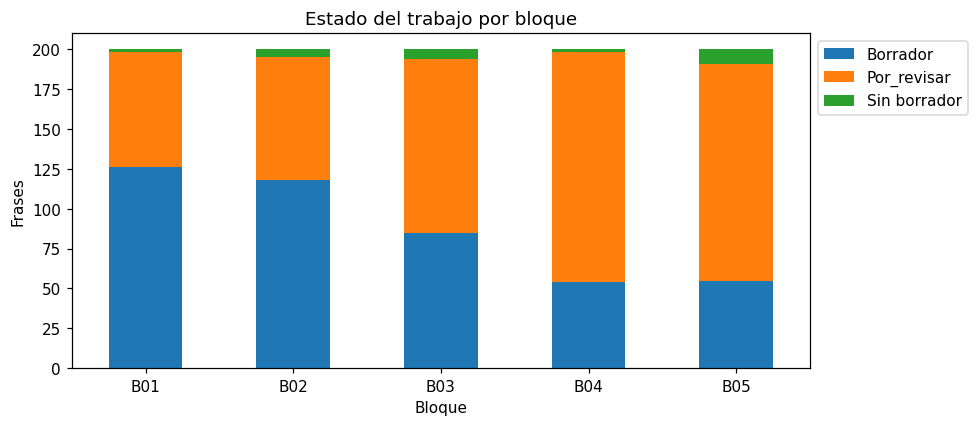

,Indicador,Filas
0,Seleccionadas,1000
1,Con borrador QU,470
2,Con texto validado QU,0
3,Elegibles por texto y estado,0


Audio/transcripción: no evaluados en este notebook. Elegibilidad textual no demuestra audio aprobado.


In [7]:
T_CALIDAD=T_REVISION.assign(Con_borrador=T_REVISION.Quechua_borrador.str.strip().ne(''),
    Con_validado=T_REVISION.Quechua_validado.str.strip().ne(''),Con_alerta=T_REVISION.N_alertas.gt(0))
T_CALIDAD['Alerta_con_borrador']=T_CALIDAD.Con_alerta & T_CALIDAD.Con_borrador
T_FUENTE_QA=T_CALIDAD.groupby('Fuente').agg(Filas=('ID','size'),Con_borrador=('Con_borrador','sum'),
    Con_validado=('Con_validado','sum'),Filas_con_alerta=('Con_alerta','sum'),Alertadas_con_borrador=('Alerta_con_borrador','sum')).reset_index()
T_FUENTE_QA['Alertadas_pct_total']=100*T_FUENTE_QA.Filas_con_alerta/T_FUENTE_QA.Filas
T_FUENTE_QA['Alertadas_pct_con_borrador']=100*T_FUENTE_QA.Alertadas_con_borrador/T_FUENTE_QA.Con_borrador.replace(0,np.nan)
display(T_FUENTE_QA.round(1))
T_ESTADOS=pd.crosstab(S.Bloque,S.Estado)
fig,ax=plt.subplots(figsize=(9,4));T_ESTADOS.plot.bar(stacked=True,ax=ax,rot=0)
ax.set(title='Estado del trabajo por bloque',ylabel='Frases');ax.legend(bbox_to_anchor=(1,1))
guardar_fig(fig,'03_estados.png')
T_PAREADO=pd.DataFrame({'Indicador':['Seleccionadas','Con borrador QU','Con texto validado QU','Elegibles por texto y estado'],
    'Filas':[len(S),S.Quechua_borrador.ne('').sum(),S.Quechua_validado.ne('').sum(),
             (S.Quechua_validado.ne('') & S.Estado.isin(['Validado','Grabado'])).sum()]})
display(T_PAREADO)
print('Audio/transcripción: no evaluados en este notebook. Elegibilidad textual no demuestra audio aprobado.')


## 7. Redundancia y contrastes útiles

Se enumeran repeticiones conservadoras y colisiones de una clave que quita tildes/signos. Las segundas **no son duplicados confirmados**. También se listan borradores quechuas compartidos por españoles distintos: puede ser una correspondencia válida o un problema de traducción.

No se calculan grupos semánticos automáticamente: requieren revisión. La tabla incluye todo el maestro para que se puedan examinar los candidatos que aún no tienen bloque.


In [8]:
D=M.assign(Clave_conservadora=M['Español'].map(clave_conservadora),Clave_flexible=M['Español'].map(clave_flexible))
exactas=D[D.Clave_conservadora.ne('') & D.duplicated('Clave_conservadora',keep=False)].copy()
flex=D.groupby('Clave_flexible').Clave_conservadora.nunique()
T_COLISIONES=D[D.Clave_flexible.isin(flex[flex.gt(1)].index)].copy()
qu=D[D.Quechua_borrador.str.strip().ne('')].copy();qu['Clave_QU']=qu.Quechua_borrador.map(clave_conservadora)
variantes=qu.groupby('Clave_QU').Clave_conservadora.nunique()
T_QU_COMPARTIDO=qu[qu.Clave_QU.isin(variantes[variantes.gt(1)].index)].sort_values('Clave_QU')
display(pd.DataFrame({'Tipo':['Filas repetidas conservadoras','Filas en colisiones flexibles','Filas con QU compartido y ES distintos'],
                     'n':[len(exactas),len(T_COLISIONES),len(T_QU_COMPARTIDO)]}))
display(T_COLISIONES[['ID','Español','Bloque','Clave_flexible']].head(15))
display(T_QU_COMPARTIDO[['ID','Español','Quechua_borrador','Bloque']].head(15))


,Tipo,n
0,Filas repetidas conservadoras,0
1,Filas en colisiones flexibles,0
2,Filas con QU compartido y ES distintos,28


,ID,Español,Bloque,Clave_flexible


,ID,Español,Quechua_borrador,Bloque
584,GEN-0586,Ellas no olvidan una fecha importante.,Paykuna huk chaniyuq punchawta mana qunqankuchu.,B02
586,GEN-0588,Ellos no olvidan una fecha importante.,Paykuna huk chaniyuq punchawta mana qunqankuchu.,
253,GEN-0255,Ellas bajan al río.,Paykuna mayuman uraykunku.,
254,GEN-0256,Ellos bajan al río.,Paykuna mayuman uraykunku.,
285,GEN-0287,Ustedes caminan con su familia.,Qamkuna ayllunwan purinkichik.,
718,GEN-0720,Ustedes viajan con su familia.,Qamkuna ayllunwan purinkichik.,
1244,CLI-0131,¿Ves bien?,¿Allintachu qawanki?,B04
1440,CLI-0327,¿Miras bien?,¿Allintachu qawanki?,
1444,CLI-0331,¿Por cuántos días menstruas?,¿Hayka punchawtataq yawarpakunki?,B05
1625,CLI-0512,¿Cuántos días le baja sangre?,¿Hayka punchawtataq yawarpakunki?,


## 8. ¿Qué aporta cada bloque y qué voces representa?

La ganancia de vocabulario se mide contra **todos los bloques anteriores**, no reiniciando el contador. La proporción general/médica y la procedencia son dimensiones diferentes. El rol heredado puede ser heurístico: la ausencia de una categoría cuidador no demuestra ausencia de esas intervenciones.


,Bloque,Filas,General,Medico,Redactado_Claude,Nuevas_formas_ES,Nuevas_formas_QU_borrador,Nuevas_formas_objetivo,Vocabulario_ES_acumulado
0,B01,200,140,60,63,492,400,391,492
1,B02,200,140,60,70,332,260,207,824
2,B03,200,140,60,101,281,179,153,1105
3,B04,200,140,60,135,222,91,108,1327
4,B05,200,140,60,135,195,66,95,1522


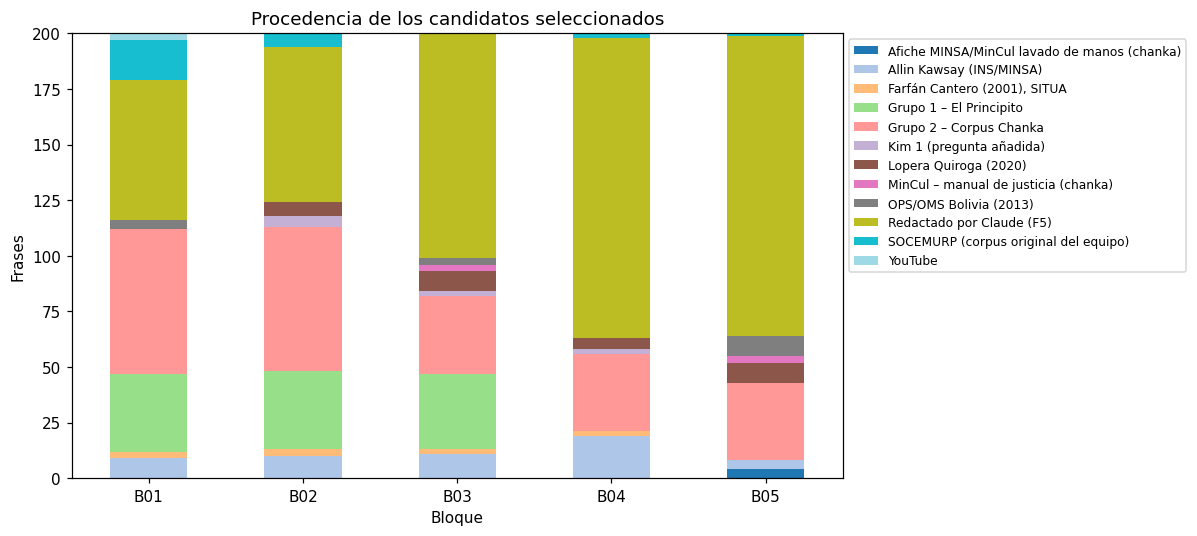

Rol,Médico,Paciente
Etapa_consulta,,
Examen físico,11,7
Explicación y plan,30,23
Inicio,9,9
Recolección de información,85,95
Relación,4,1
Sensible,13,13


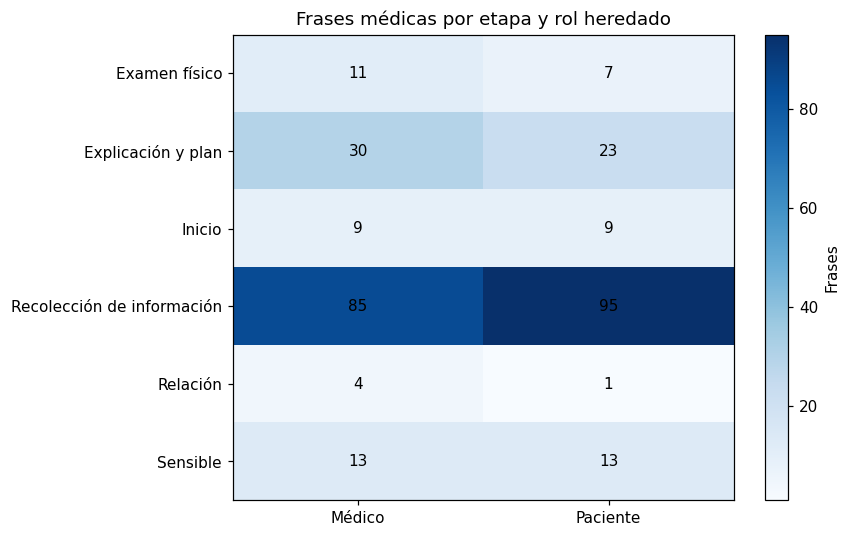

In [9]:
seen_es=set();seen_qu=set();bloques=[]
for b,g in S.groupby('Bloque',sort=True):
    ve=vocab(g['Español']);vq=vocab(g.Quechua_borrador)
    bloques.append({'Bloque':b,'Filas':len(g),'General':g.Dominio.eq('General').sum(),'Medico':g.Dominio.eq('Médico').sum(),
        'Redactado_Claude':g.Fuente.str.contains('Redactado por Claude',regex=False).sum(),
        'Nuevas_formas_ES':len(ve-seen_es),'Nuevas_formas_QU_borrador':len(vq-seen_qu),
        'Nuevas_formas_objetivo':len((ve-seen_es)&OBJETIVO),'Vocabulario_ES_acumulado':len(seen_es|ve)})
    seen_es|=ve;seen_qu|=vq
T_BLOQUES=pd.DataFrame(bloques)
T_FUENTES=pd.crosstab(S.Bloque,S.Fuente)
display(T_BLOQUES)
fig,ax=plt.subplots(figsize=(11,5));T_FUENTES.plot.bar(stacked=True,ax=ax,rot=0,colormap='tab20')
ax.set(title='Procedencia de los candidatos seleccionados',ylabel='Frases');ax.legend(bbox_to_anchor=(1,1),fontsize=8)
guardar_fig(fig,'04_fuentes_bloques.png')
T_ROLES=pd.crosstab(S[S.Dominio.eq('Médico')].Etapa_consulta,S[S.Dominio.eq('Médico')].Rol)
display(T_ROLES)
fig,ax=plt.subplots(figsize=(8,5));im=ax.imshow(T_ROLES.to_numpy(),cmap='Blues',aspect='auto')
ax.set_xticks(range(len(T_ROLES.columns)),T_ROLES.columns);ax.set_yticks(range(len(T_ROLES.index)),T_ROLES.index)
for i in range(len(T_ROLES)):
    for j in range(len(T_ROLES.columns)): ax.text(j,i,str(T_ROLES.iloc[i,j]),ha='center',va='center',color='black')
ax.set_title('Frases médicas por etapa y rol heredado');fig.colorbar(im,ax=ax,label='Frases')
guardar_fig(fig,'05_etapas_roles.png')


## 9. Pares de diálogo y preparación de evaluación

Se verifica que las respuestas tengan su pregunta en el mismo bloque/sublote. Se muestran las particiones reales: `Test_sugerido` no es un test reservado mientras `Split` siga siendo train. Los grupos con el mismo borrador QU o clave flexible que cruzan splits son candidatos a revisión, no prueba suficiente de fuga semántica.

No se inventan divisiones por hablante porque esos metadatos aún no están disponibles en el maestro. Tampoco se cambian los splits.


In [10]:
lookup=M.set_index('ID');pares=[]
for r in S[S.Responde_a.ne('')].to_dict('records'):
    q=r['Responde_a'];existe=q in lookup.index
    pares.append({'Respuesta_ID':r['ID'],'Pregunta_ID':q,'Bloque':r['Bloque'],'Sublote':r['Sublote'],
        'Pregunta_ES':lookup.loc[q,'Español'] if existe else '', 'Respuesta_ES':r['Español'],
        'Pregunta_existe':existe,'Mismo_bloque':bool(existe and lookup.loc[q,'Bloque']==r['Bloque']),
        'Mismo_sublote':bool(existe and lookup.loc[q,'Sublote']==r['Sublote'])})
T_PARES=pd.DataFrame(pares,columns=['Respuesta_ID','Pregunta_ID','Bloque','Sublote','Pregunta_ES','Respuesta_ES','Pregunta_existe','Mismo_bloque','Mismo_sublote'])
T_SPLITS=pd.crosstab(C.Split,C.Test_sugerido)
display(T_SPLITS); display(T_PARES.head(12))
print('Pares con problemas estructurales:',int((~T_PARES[['Pregunta_existe','Mismo_bloque','Mismo_sublote']].all(axis=1)).sum()))
if set(C.Split)=={'train'}: print('No hay evaluación independiente definida en el maestro.')
cross=D.groupby('Clave_flexible').Split.nunique()
T_CRUCES=D[D.Clave_flexible.isin(cross[cross.gt(1)].index)].copy()
cross_qu=qu.groupby('Clave_QU').Split.nunique()
T_CRUCES_QU=qu[qu.Clave_QU.isin(cross_qu[cross_qu.gt(1)].index)].copy()


Test_sugerido,No,Sí
Split,,
train,2154,100


,Respuesta_ID,Pregunta_ID,Bloque,Sublote,Pregunta_ES,Respuesta_ES,Pregunta_existe,Mismo_bloque,Mismo_sublote
0,CLI-0978,CLI-0745,B01,B01-S1,Buenos días.,"Buenos días, doctor.",True,True,True
1,CLI-0002,CLI-0001,B01,B01-S1,¿Cómo estás?,No estoy bien.,True,True,True
2,CLI-0012,CLI-0011,B01,B01-S1,¿Cómo te llamas?,Mi nombre es Annel.,True,True,True
3,CLI-0016,CLI-0015,B01,B01-S1,¿Cuántos años tienes?,Yo tengo veinte años.,True,True,True
4,CLI-0020,CLI-0019,B01,B01-S1,¿De dónde eres?,Soy de Ayacucho.,True,True,True
5,CLI-0008,CLI-0025,B01,B01-S1,¿Por qué viniste al hospital?,Me está doliendo la barriga.,True,True,True
6,CLI-0979,CLI-0033,B01,B01-S1,¿Desde cuándo estás enferma?,Desde hace tres días.,True,True,True
7,CLI-0980,CLI-0035,B01,B01-S1,¿Cómo empezó tu enfermedad?,"Empezó de repente, después de comer.",True,True,True
8,CLI-0029,CLI-0028,B01,B01-S2,¿Cómo te sientes?,Me siento enferma.,True,True,True
9,CLI-0981,CLI-0042,B01,B01-S2,¿Dónde te duele?,"Aquí, en la boca del estómago.",True,True,True


Pares con problemas estructurales: 0
No hay evaluación independiente definida en el maestro.


## 10. Muestra para calibrar el EDA con revisión humana

Se muestrean hasta dos ejemplos por combinación bloque × fuente × presencia de alerta, con semilla fija. El tamaño resultante depende de los estratos. Es una **muestra diagnóstica**, sobrerrepresenta fuentes pequeñas y no estima por sí sola una tasa global de error.

La plantilla incluye español y ambos campos quechua separados. Completar claridad, autonomía, naturalidad, lectura, utilidad, equivalencia, contexto clínico y decisión. Usar `Sí / No / Dudoso / No aplica`; registrar también problemas encontrados aunque no hubiera alertas.

Revisar la cobertura morfológica en una etapa posterior con traducciones aprobadas. No se convierte la segmentación heurística de borradores en análisis morfológico validado ni en cobertura fonética.


In [11]:
trozos=[]
for _,g in T_REVISION.groupby(['Bloque','Fuente','Tiene_senal_revision'],sort=True):
    trozos.append(g.sample(n=min(2,len(g)),random_state=SEED))
MUESTRA=pd.concat(trozos,ignore_index=True).sort_values(['Bloque','ID'])
columnas=['ID','Bloque','Fuente','Español','Quechua_borrador','Quechua_validado','Estado','Tipos_QA','Nota_editorial','Tiene_senal_revision']
PLANTILLA=MUESTRA[columnas].copy()
for k in ['Claridad','Autonomia','Naturalidad','Facilidad_lectura','Utilidad','Equivalencia_par','Adecuacion_clinica',
          'Alerta_confirmada','Problema_no_alertado','Decision','Comentario','Revisor','Fecha']:
    PLANTILLA[k]=''
PLANTILLA['Version_maestro_SHA256']=huellas[str(entradas[0])]
display(PLANTILLA.head(10)); print('Frases en la muestra diagnóstica:',len(PLANTILLA))


,ID,Bloque,Fuente,Español,Quechua_borrador,Quechua_validado,Estado,Tipos_QA,Nota_editorial,Tiene_senal_revision,Claridad,Autonomia,Naturalidad,Facilidad_lectura,Utilidad,Equivalencia_par,Adecuacion_clinica,Alerta_confirmada,Problema_no_alertado,Decision,Comentario,Revisor,Fecha,Version_maestro_SHA256
24,CLI-0002,B01,YouTube,No estoy bien.,Manam allinchu kani.,,Borrador,,,False,,,,,,,,,,,,,,ca52cc9383e92560a5c95f48b532340c2645ed10977e2d...
25,CLI-0008,B01,YouTube,Me está doliendo la barriga.,Wiksaymi nanawachkan.,,Borrador,,,False,,,,,,,,,,,,,,ca52cc9383e92560a5c95f48b532340c2645ed10977e2d...
23,CLI-0011,B01,SOCEMURP (corpus original del equipo),¿Cómo te llamas?,¿Imataq sutiyki?,,Borrador,DUP,,True,,,,,,,,,,,,,,ca52cc9383e92560a5c95f48b532340c2645ed10977e2d...
22,CLI-0015,B01,SOCEMURP (corpus original del equipo),¿Cuántos años tienes?,¿Haykataq watayki?,,Borrador,DUP,,True,,,,,,,,,,,,,,ca52cc9383e92560a5c95f48b532340c2645ed10977e2d...
20,CLI-0029,B01,SOCEMURP (corpus original del equipo),Me siento enferma.,Unqusqa kachkani.,,Borrador,,,False,,,,,,,,,,,,,,ca52cc9383e92560a5c95f48b532340c2645ed10977e2d...
21,CLI-0097,B01,SOCEMURP (corpus original del equipo),Respira hondo.,Samay ukumanta.,,Por_revisar,,,False,,,,,,,,,,,,,,ca52cc9383e92560a5c95f48b532340c2645ed10977e2d...
4,CLI-0127,B01,"Farfán Cantero (2001), SITUA",¿Tienes fiebre?,¿Rupapakunkichu?,,Borrador,,,False,,,,,,,,,,,,,,ca52cc9383e92560a5c95f48b532340c2645ed10977e2d...
6,CLI-0135,B01,"Farfán Cantero (2001), SITUA",¿Tienes vómitos?,¿Wikchunayasunkichu?,,Borrador,DUP,,True,,,,,,,,,,,,,,ca52cc9383e92560a5c95f48b532340c2645ed10977e2d...
5,CLI-0141,B01,"Farfán Cantero (2001), SITUA",¿Te duele mucho?,¿Sinchitachu nanasunki?,,Borrador,,,False,,,,,,,,,,,,,,ca52cc9383e92560a5c95f48b532340c2645ed10977e2d...
1,CLI-0153,B01,Allin Kawsay (INS/MINSA),Toma líquido.,Yakuta upyay,,Borrador,,,False,,,,,,,,,,,,,,ca52cc9383e92560a5c95f48b532340c2645ed10977e2d...


Frases en la muestra diagnóstica: 119


## 11. Exportaciones y comprobaciones

`EDA_POSTSELECCION.xlsx` es un informe automático y se regenera. **No anotar decisiones humanas en ese archivo.** `REVISION_HUMANA.xlsx` se crea solo si no existe; si cambia el maestro, se conserva el archivo anterior y se advierte que se debe conciliar por ID y texto.

El informe no reemplaza `02_maestro/corpus_maestro.xlsx`, ni los Word entregados. Para decidir qué grabar se necesita cerrar revisión del español y quechua, y después comprobar audio y transcripción.


In [12]:
tablas={'Etapas':T_ETAPAS,'Dominio_rol_etapa':T_DISTRIBUCIONES,'Fuentes_por_etapa':T_FUENTES_ETAPA,'Carga_flashcards':pd.DataFrame(carga_flash),
 'Referencias_todas':REF_TODAS,'Cobertura_flashcards':T_COBERTURA,'Cobertura_por_archivo':T_COBERTURA_ARCHIVO,'Palabras_objetivo':T_PALABRAS,
 'Curva_cobertura':T_CURVA,'Candidatos_referencia':T_RECUPERADAS,'Revision_seleccion':T_REVISION,
 'QA_por_fuente':T_FUENTE_QA,'Estado_pareado':T_PAREADO,'Duplicados_conservadores':exactas,
 'Colisiones_flexibles':T_COLISIONES,'QU_compartido':T_QU_COMPARTIDO,'Bloques':T_BLOQUES,
 'Fuentes_por_bloque':T_FUENTES.reset_index(),'Roles_etapas':T_ROLES.reset_index(),
 'Pares_dialogo':T_PARES,'Cruces_split_flexible':T_CRUCES,'Cruces_split_QU':T_CRUCES_QU,'Muestra_automatica':PLANTILLA}

def escribir_excel(path,tablas):
    with pd.ExcelWriter(path,engine='openpyxl') as w:
        for nombre,df in tablas.items():
            df.to_excel(w,sheet_name=nombre,index=False)
            ws=w.sheets[nombre];ws.freeze_panes='A2';ws.auto_filter.ref=ws.dimensions
            # Cadenas del corpus son datos, nunca fórmulas ejecutables del Excel.
            for row in ws.iter_rows():
                for cell in row:
                    if cell.data_type=='f': cell.data_type='s'
            for col in ws.columns:
                ws.column_dimensions[col[0].column_letter].width=min(55,max(14,len(str(col[0].value or ''))+2))

assert len(T_REVISION)==len(S) and T_REVISION.ID.is_unique
assert len(T_RECUPERADAS)==len(REF)
claves_maestro=set(M['Español'].map(clave_conservadora))
assert int(T_RECUPERADAS.Coincidencia_exacta.sum())==int(REF.Clave.isin(claves_maestro).sum()), 'La recuperación perdió coincidencias exactas.'
rec=T_RECUPERADAS[T_RECUPERADAS.ID.fillna('').ne('')]
for campo in ['Español','Quechua_borrador','Quechua_validado']:
    assert rec[campo].tolist()==M.set_index('ID').loc[rec.ID,campo].tolist(), 'Se alteró un par recuperado.'
assert T_CURVA.cobertura_pct.is_monotonic_increasing
assert T_CURVA.cobertura_pct.between(0,100).all()
assert abs(T_CURVA.cobertura_pct.iloc[-1]-T_COBERTURA.set_index('Etapa').loc['Seleccionado','Cobertura_tipos_pct'])<1e-9
assert set(PLANTILLA.ID).issubset(set(S.ID))
assert all(sha(p)==h for p,h in huellas.items()), 'Cambió una entrada durante la ejecución.'
escribir_excel(OUT/'EDA_POSTSELECCION.xlsx',tablas)
humano=OUT/'REVISION_HUMANA.xlsx'
if not humano.exists():
    escribir_excel(humano,{'Revision':PLANTILLA});print('Plantilla humana creada.')
else:
    print('Se conserva REVISION_HUMANA.xlsx sin modificar. Compara su huella de maestro con la actual antes de reutilizarla.')
manifest={'ejecucion_utc':datetime.now(timezone.utc).isoformat(),'maestro_sha256':huellas[str(entradas[0])],
    'entradas':huellas,'semilla':SEED,'max_palabras_alerta':MAX_PALABRAS_ALERTA,'filas_maestro':len(M),
    'filas_seleccionadas':len(S),'referencias_unicas':len(REF),'vocabulario_objetivo':len(OBJETIVO),
    'cobertura_seleccion_pct':float(T_CURVA.cobertura_pct.iloc[-1]),'tamano_muestra':len(PLANTILLA),
    'validaciones':'IDs, versiones F5/maestro, cobertura acumulada, muestra e integridad de entradas: OK',
    'versiones':{'pandas':pd.__version__,'numpy':np.__version__}}
(OUT/'ejecucion.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
print('Exportado:',OUT/'EDA_POSTSELECCION.xlsx')
print(json.dumps({k:manifest[k] for k in ['filas_maestro','filas_seleccionadas','referencias_unicas','vocabulario_objetivo','cobertura_seleccion_pct','tamano_muestra']},ensure_ascii=False,indent=2))
faltantes=int(T_PALABRAS.Situacion.eq('disponible_no_seleccionada').sum())
lineas=['# Resultados del EDA posterior a la selección','',
    f'- Maestro: {len(M)} filas; seleccionadas: {len(S)}.',
    f'- Referencias españolas únicas de las flashcards: {len(REF)}; formas escritas objetivo: {len(OBJETIVO)}.',
    f'- Cobertura de formas objetivo de la selección: {manifest["cobertura_seleccion_pct"]:.2f}%.',
    f'- Formas objetivo presentes en el maestro, pero ausentes de la selección: {faltantes}.',
    f'- Referencias con coincidencia exacta conservadora en el maestro: {int(T_RECUPERADAS.Coincidencia_exacta.sum())}.',
    f'- Muestra diagnóstica para revisión humana: {len(PLANTILLA)} frases.',
    f'- Filas seleccionadas con quechua validado no vacío: {int(S.Quechua_validado.ne("").sum())}.','',
    '## Interpretación','',
    'La cobertura mide formas escritas, conserva tildes y flexiones y no demuestra equivalencia semántica. '
    'Las dos flashcards tienen tamaños y contenidos diferentes: consultar Cobertura_por_archivo antes de interpretar la cifra combinada. '
    'Las traducciones de las flashcards corresponden a otra lengua y no se importan como quechua.','',
    'Las formas disponibles no seleccionadas son oportunidades de búsqueda, '
    'no una orden de reemplazar frases. Priorizar utilidad, claridad y validación del par antes de maximizar cobertura.','',
    '## Archivos','',
    '- EDA_POSTSELECCION.xlsx: resultados automáticos, se sobrescribe al ejecutar.',
    '- REVISION_HUMANA.xlsx: plantilla creada una sola vez; las siguientes ejecuciones la conservan.',
    '- fig/: cinco gráficos.',
    '- ejecucion.json: entradas, huellas, parámetros y comprobaciones.','',
    'No hay calificaciones humanas inventadas. Las alertas y las coincidencias léxicas necesitan revisión. '
    'Las decisiones del Excel humano no se importan automáticamente al maestro.']
(OUT/'RESULTADOS.md').write_text('\n'.join(lineas)+'\n',encoding='utf-8')


Se conserva REVISION_HUMANA.xlsx sin modificar. Compara su huella de maestro con la actual antes de reutilizarla.
Exportado: C:\Users\PC\Desktop\GestionConocimientoTA\DataRecolectada\EDA_AnalisisFinal\Corpus_Quechua\04_reportes\eda_postseleccion\EDA_POSTSELECCION.xlsx
{
  "filas_maestro": 2254,
  "filas_seleccionadas": 1000,
  "referencias_unicas": 8247,
  "vocabulario_objetivo": 4627,
  "cobertura_seleccion_pct": 20.61811108709747,
  "tamano_muestra": 119
}


## Cómo usar estos resultados

1. Revisar `Etapas` para entender las poblaciones y los cambios de composición.
2. Abrir `Palabras_objetivo`: priorizar palabras disponibles pero no seleccionadas antes de redactar más español.
3. Consultar `Candidatos_referencia` preservando el par y su procedencia. No copiar una traducción a un español diferente.
4. Revisar `Revision_seleccion`, `Pares_dialogo` y la muestra con el traductor; las alertas no son decisiones.
5. Completar `REVISION_HUMANA.xlsx`. Conciliar decisiones con el maestro mediante una operación posterior revisada; este notebook no importa cambios.
6. Recalcular cobertura del quechua cuando haya traducciones aprobadas, y añadir análisis de audio cuando existan tomas identificadas y transcritas.

Pendiente: equivalencia semántica humana, validación de rasgos morfológicos, similitud semántica/paráfrasis revisadas, particiones de evaluación y calidad acústica. No se presentan estos componentes como resueltos por coincidencias léxicas.
